Random Forest Model - Baseline model

In [ ]:

import numpy as np
import pandas as pd
import optuna
import os
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

base_dir = os.getcwd()
consolidated_datapath = os.path.join(base_dir,'consolidated_data')

train_df = pd.read_csv(f'{consolidated_datapath}/train_consolidated.csv')
test_df = pd.read_csv(f'{consolidated_datapath}/test_consolidated.csv')
target = "Survived"

scoring = "roc_auc"
cv_folds = 5
n_trials = 30
seed = 42

X_train = train_df.drop(columns=[target],inplace=False)
y_train = train_df[target]
X_test = test_df.drop('PassengerId',axis=1,inplace=False)
y_test = test_df[target] if target in test_df.columns else None

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

def build_model(params):
    return Pipeline([
        ("prep", preprocess),
        ("rf", RandomForestClassifier(random_state=seed, n_jobs=-1, **params)),
    ])

# cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=seed)
from sklearn.model_selection import StratifiedShuffleSplit

n_splits = 20      # your choice: number of random splits
val_size = 0.2     # your choice: fraction of rows held out in each split

cv = StratifiedShuffleSplit(n_splits=n_splits, test_size=val_size, random_state=seed)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "max_depth": trial.suggest_int("max_depth", 3, 30),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 1.0]),
        "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }
    scores = cross_val_score(build_model(params), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    return scores.mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

print("Best CV score:", study.best_value, f"({scoring}, higher is better)")
print("Best params:", study.best_params)

best_model = build_model(study.best_params).fit(X_train, y_train)
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

if y_test is not None:
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test Precision:", precision_score(y_test, y_pred))
    print("Test Recall:", recall_score(y_test, y_pred))
    print("Test F1:", f1_score(y_test, y_pred))
    print("Test ROC-AUC:", roc_auc_score(y_test, y_prob))


[I 2026-11-20 13:43:40,512] A new study created in memory with name: no-name-9efa32f6-2e92-4907-92ee-9744433fcbaa
Best trial: 0. Best value: 0.863585:   3%|▎         | 1/30 [00:15<07:22, 15.25s/it]

[I 2026-11-20 13:43:55,751] Trial 0 finished with value: 0.8635851926977688 and parameters: {'n_estimators': 362, 'max_depth': 29, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'bootstrap': True, 'class_weight': None}. Best is trial 0 with value: 0.8635851926977688.


Best trial: 0. Best value: 0.863585:   7%|▋         | 2/30 [00:51<12:54, 27.66s/it]

[I 2026-11-20 13:44:32,092] Trial 1 finished with value: 0.85276369168357 and parameters: {'n_estimators': 779, 'max_depth': 26, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': 1.0, 'bootstrap': True, 'class_weight': None}. Best is trial 0 with value: 0.8635851926977688.


Best trial: 0. Best value: 0.863585:  10%|█         | 3/30 [01:02<09:05, 20.20s/it]

[I 2026-11-20 13:44:43,426] Trial 2 finished with value: 0.8304969574036513 and parameters: {'n_estimators': 304, 'max_depth': 13, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': 1.0, 'bootstrap': False, 'class_weight': None}. Best is trial 0 with value: 0.8635851926977688.


... (46 outputs left out)

Best trial: 23. Best value: 0.866805:  90%|█████████ | 27/30 [06:26<00:25,  8.44s/it]

[I 2026-11-20 13:50:07,018] Trial 26 finished with value: 0.864284989858012 and parameters: {'n_estimators': 224, 'max_depth': 18, 'min_samples_split': 3, 'min_samples_leaf': 7, 'max_features': 'sqrt', 'bootstrap': False, 'class_weight': None}. Best is trial 23 with value: 0.8668052738336713.


Best trial: 23. Best value: 0.866805:  93%|█████████▎| 28/30 [06:43<00:22, 11.07s/it]

[I 2026-11-20 13:50:24,234] Trial 27 finished with value: 0.859792089249493 and parameters: {'n_estimators': 388, 'max_depth': 10, 'min_samples_split': 6, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'bootstrap': True, 'class_weight': None}. Best is trial 23 with value: 0.8668052738336713.


Training results:

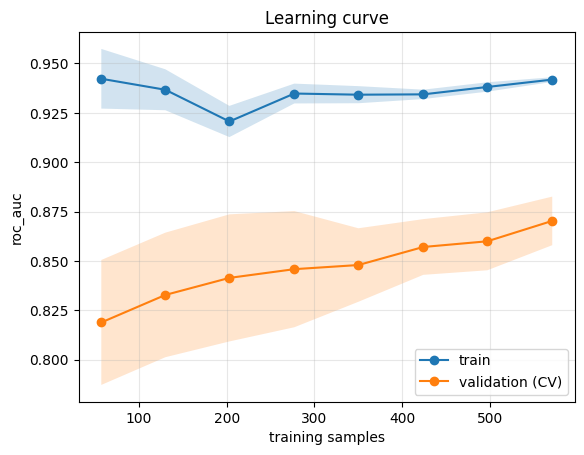

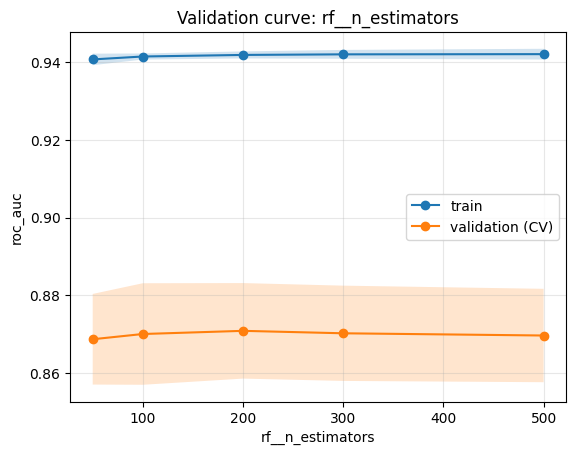

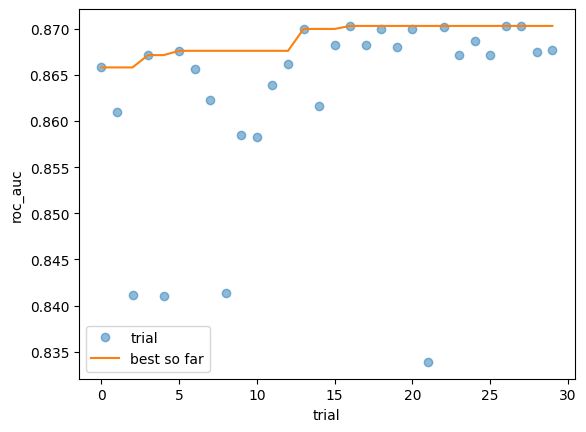

In [14]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, validation_curve
from sklearn.ensemble import RandomForestClassifier

def plot_curve(x, train_scores, val_scores, xlabel, title):
    for scores, label in [(train_scores, "train"), (val_scores, "validation (CV)")]:
        m, s = scores.mean(axis=1), scores.std(axis=1)
        plt.plot(x, m, marker="o", label=label)
        plt.fill_between(x, m - s, m + s, alpha=0.2)
    plt.xlabel(xlabel); plt.ylabel(scoring); plt.title(title); plt.legend(); plt.grid(alpha=.3)
    plt.show()

# 1) Learning curve: score vs. training set size (using the best params)
sizes, tr, va = learning_curve(
    build_model(study.best_params), X_train, y_train,
    cv=cv, scoring=scoring, train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=1,
)
plot_curve(sizes, tr, va, "training samples", "Learning curve")

# 2) Validation curve: score vs. one hyperparameter (others fixed at best values)
param_name = "rf__n_estimators" 
param_range = [50, 100, 200, 300, 500]
tr, va = validation_curve(
    build_model(study.best_params), X_train, y_train,
    param_name=param_name, param_range=param_range,
    cv=cv, scoring=scoring, n_jobs=1,
)
plot_curve(param_range, tr, va, param_name, f"Validation curve: {param_name}")

# 3) Optuna: tuning history (best score as trials progress)
df_trials = study.trials_dataframe()
plt.plot(df_trials["number"], df_trials["value"], "o", alpha=.5, label="trial")
plt.plot(df_trials["number"], df_trials["value"].cummax(), label="best so far")
plt.xlabel("trial"); plt.ylabel(scoring); plt.legend(); plt.show()


Submission:

In [11]:

submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": y_pred.astype(int)
})

submission.to_csv(f"{base_dir}/consolidated_data/submission.csv", index=False)